# 04.3 · Missing values and outliers done properly

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/04-trustworthy-models/03-missing-and-outliers/lesson.ipynb)

Read the [README](README.md) first. This notebook:

1. finds the missing values in ShopWave's raw data and asks *why* they are missing,
2. fills gaps by hand, then with `SimpleImputer` fitted on training rows only,
3. shows that "missing" can itself be a strong signal (a missing-indicator column),
4. detects outliers with the IQR and z-score rules, and shows how the z-score can be fooled,
5. compares dropping, capping and log-transforming outliers in a churn model.

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail()                                   # ~1 s after the first run
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

def customer_table(cutoff, months=3):
    """One row per customer: features from before `cutoff`, churned = no order in the next `months`."""
    cutoff = pd.Timestamp(cutoff)
    past = sales[sales["InvoiceDate"] < cutoff]
    future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < cutoff + pd.DateOffset(months=months))]
    c = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                        products=("StockCode", "nunique"), country=("Country", "first"),
                                        first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
    c["tenure_days"] = (cutoff - c["first_order"]).dt.days
    c["days_since_last"] = (cutoff - c["last_order"]).dt.days
    came_back = future.groupby("Customer ID")["Revenue"].sum().reindex(c.index).fillna(0) > 0
    c["churned"] = (~came_back).astype(int)
    return c.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
cust = customer_table("2011-09-01")
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}")

3,317 customers, churn rate 43.6%


## 1. Where is data missing, and why?

Start with the raw transactions.

In [2]:
print(raw.isna().mean().mul(100).round(2).sort_values(ascending=False).head(3).to_string())

Customer ID    24.93
Description     0.27
Invoice         0.00


In [3]:
by_country = raw.assign(no_id=raw["Customer ID"].isna()).groupby("Country")["no_id"].agg(["mean", "size"])
by_country[by_country["size"] > 5000].sort_values("mean").round(3)

,mean,size
Country,,
Germany,0.000,9495
France,0.008,8558
EIRE,0.087,8196
United Kingdom,0.270,495478


A quarter of transactions have no `Customer ID` (guest checkouts), and the rate depends strongly on the country. That is **missing at random (MAR)** in the statistician's sense: the missingness is explained by something we can see (country). Dropping those rows, as we do for customer-level models, removes UK guest buyers far more than German ones. That is fine for a churn model (guests cannot churn: we cannot recognise them), but it would bias a *revenue* report by country.

## 2. Filling gaps by hand

Eight customers, two columns, three gaps in each.

In [4]:
gap = pd.Series([12, 20, np.nan, 30, np.nan, 45, 90, np.nan], name="avg_gap_days")
country = pd.Series(["UK", "UK", "DE", np.nan, "UK", "FR", np.nan, "UK"], name="country")

pd.concat([gap, country], axis=1)

,avg_gap_days,country
0,12.0,UK
1,20.0,UK
2,NaN,DE
3,30.0,NaN
4,NaN,UK
5,45.0,FR
6,90.0,NaN
7,NaN,UK


In [5]:
print("mean of known gaps:  ", gap.mean())          # (12+20+30+45+90)/5
print("median of known gaps:", gap.median())
print("mode of country:     ", country.mode()[0])

filled = pd.DataFrame({
    "original": gap, "mean": gap.fillna(gap.mean()), "median": gap.fillna(gap.median()),
    "constant -1": gap.fillna(-1), "was_missing": gap.isna().astype(int)})
filled

mean of known gaps:   39.4
median of known gaps: 30.0
mode of country:      UK


,original,mean,median,constant -1,was_missing
0,12.0,12.0,12.0,12.0,0
1,20.0,20.0,20.0,20.0,0
2,NaN,39.4,30.0,-1.0,1
3,30.0,30.0,30.0,30.0,0
4,NaN,39.4,30.0,-1.0,1
5,45.0,45.0,45.0,45.0,0
6,90.0,90.0,90.0,90.0,0
7,NaN,39.4,30.0,-1.0,1


The mean is pulled up by the 90; the median is not. Notice what every fill method does: it **invents** a number and the model cannot tell it from a real one, unless you also add the `was_missing` column.

## 3. A missing value that tells the truth

`avg_gap_days`, the average number of days between a customer's orders, is a natural churn feature. It cannot be computed for a customer with only one order.

In [6]:
past = sales[sales["InvoiceDate"] < "2011-09-01"]
span = past.groupby("Customer ID")["InvoiceDate"].agg(["min", "max"])
days_active = (span["max"] - span["min"]).dt.days.reindex(cust.index)
# average days between orders; undefined (missing) for customers with only one order
cust["avg_gap_days"] = (days_active / (cust["orders"] - 1)).where(cust["orders"] > 1)
print(f"avg_gap_days missing for {cust['avg_gap_days'].isna().mean():.1%} of customers")

avg_gap_days missing for 41.5% of customers


In [7]:
print(cust.groupby(cust["avg_gap_days"].isna())["churned"].mean().rename({False: "has avg_gap", True: "missing"}).round(3))

avg_gap_days
has avg_gap    0.302
missing        0.625
Name: churned, dtype: float64


Customers with a missing gap churn **twice as often**. The value is missing *because* the customer bought only once, and one-time buyers are the ones who leave. This is **missing not at random (MNAR)**: the reason it is missing is linked to what we are predicting. Filling it with the median would erase the signal; a missing-indicator column keeps it.

## 4. `SimpleImputer`, fitted on training rows only

In [8]:
from sklearn.model_selection import train_test_split
cols = ["days_since_last", "avg_gap_days"]
X_tr, X_te, y_tr, y_te = train_test_split(cust[cols], cust["churned"], test_size=0.25,
                                          random_state=42, stratify=cust["churned"])

from sklearn.impute import SimpleImputer
imp = SimpleImputer(strategy="median").fit(X_tr)          # learns the median from TRAIN rows
print("medians learned from train:", dict(zip(cols, imp.statistics_)))
print("median of the full column (not used):", cust["avg_gap_days"].median())

medians learned from train: {'days_since_last': np.float64(72.0), 'avg_gap_days': np.float64(46.5)}
median of the full column (not used): 45.333333333333336


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

def churn_score(strategy, indicator):
    imp = SimpleImputer(strategy=strategy, add_indicator=indicator).fit(X_tr)
    sc = StandardScaler().fit(imp.transform(X_tr))                 # scaling: lesson 04.5
    lr = LogisticRegression().fit(sc.transform(imp.transform(X_tr)), y_tr)
    return lr.score(sc.transform(imp.transform(X_te)), y_te)

for strategy in ["mean", "median"]:
    for indicator in [False, True]:
        print(f"{strategy:<6}  indicator={str(indicator):<5}  test accuracy {churn_score(strategy, indicator):.1%}")

mean    indicator=False  test accuracy 64.3%
mean    indicator=True   test accuracy 65.5%
median  indicator=False  test accuracy 64.9%
median  indicator=True   test accuracy 65.7%


Median beats mean slightly (the gaps are skewed), and adding the indicator helps both, by about one point (mean 64.3% → 65.5%, median 64.9% → 65.7%). The gain is modest here because `days_since_last` already carries much of the same information; on datasets where "missing" is the main clue, the indicator can be worth far more.

## 5. Outliers by hand: IQR vs z-score

Eight customers' quarterly spend, one of them a wholesaler.

In [10]:
spend8 = pd.Series([120, 150, 180, 200, 240, 260, 300, 4800], name="spend")

q1, q3 = np.percentile(spend8, [25, 75])
iqr = q3 - q1
print(f"Q1={q1}, Q3={q3}, IQR={iqr}, upper fence = Q3 + 1.5×IQR = {q3 + 1.5*iqr}")
print("IQR outliers:", spend8[spend8 > q3 + 1.5 * iqr].tolist())

Q1=172.5, Q3=270.0, IQR=97.5, upper fence = Q3 + 1.5×IQR = 416.25
IQR outliers: [4800]


In [11]:
mean, std = spend8.mean(), spend8.std()
z = (spend8 - mean) / std
print(f"mean = {mean:.2f}, std = {std:.2f}")
print(pd.DataFrame({"spend": spend8, "z": z.round(2)}).T.to_string())
print("z > 3 outliers:", spend8[z.abs() > 3].tolist(), " ← none!")

mean = 781.25, std = 1624.88
            0       1       2       3       4       5      6        7
spend  120.00  150.00  180.00  200.00  240.00  260.00  300.0  4800.00
z       -0.41   -0.39   -0.37   -0.36   -0.33   -0.32   -0.3     2.47
z > 3 outliers: []  ← none!


The z-score misses the wholesaler. One extreme value inflates both the mean and the standard deviation, so it ends up only 2.47 standard deviations from a mean it has dragged towards itself. This is called **masking**. Quartiles barely move when one value goes wild, which is why the IQR rule is the safer default on skewed data like spend.

## 6. Outliers in the real churn table

In [12]:
s = cust["spend"]
q1, q3 = s.quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
z = (s - s.mean()) / s.std()
print(f"IQR upper fence £{fence:,.0f}: {(s > fence).sum()} customers ({(s > fence).mean():.1%})")
print(f"z > 3: {(z > 3).sum()} customers")
cust.sort_values("spend", ascending=False)[["orders", "spend", "products", "country", "churned"]].head(5)

IQR upper fence £3,000: 293 customers (8.8%)
z > 3: 27 customers


,orders,spend,products,country,churned
Customer ID,,,,,
14646.0,40,176355.94,492,Netherlands,0
18102.0,26,130537.23,54,United Kingdom,0
12415.0,13,99146.16,377,Australia,0
17450.0,22,85610.34,107,United Kingdom,0
14156.0,35,84977.35,596,EIRE,0


293 "outliers" by the IQR rule: far too many to be errors. They are ShopWave's best customers, mostly wholesale buyers, and the top five all came back. Deleting them would delete the most important people in the business. An outlier is a question ("is this an error or a real extreme?"), not an instruction to delete.

## 7. Three treatments compared

Keep every customer, and change only how `spend` is presented to a logistic regression.

In [13]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"train {len(X_train):,} / test {len(X_test):,}")

def logistic_score(transform):
    Xa = X_train[["days_since_last"]].assign(spend=transform(X_train["spend"]))
    Xb = X_test[["days_since_last"]].assign(spend=transform(X_test["spend"]))
    sc = StandardScaler().fit(Xa)
    return LogisticRegression().fit(sc.transform(Xa), y_train).score(sc.transform(Xb), y_test)

cap = X_train["spend"].quantile(0.99)                       # fence learned from TRAIN rows
for name, f in [("raw spend", lambda x: x), ("capped at train 99th pct", lambda x: x.clip(upper=cap)),
                ("log(1 + spend)", np.log1p)]:
    print(f"{name:<26} test accuracy {logistic_score(f):.1%}")

train 2,487 / test 830
raw spend                  test accuracy 64.2%
capped at train 99th pct   test accuracy 64.6%
log(1 + spend)             test accuracy 67.3%


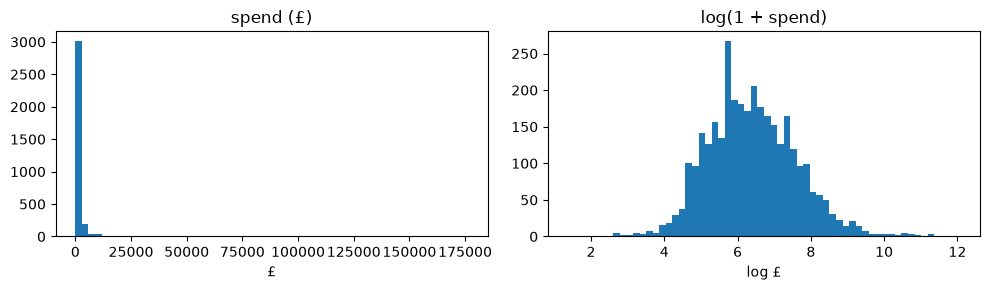

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(cust["spend"], bins=60); axes[0].set(title="spend (£)", xlabel="£")
axes[1].hist(np.log1p(cust["spend"]), bins=60); axes[1].set(title="log(1 + spend)", xlabel="log £")
plt.tight_layout(); plt.show()

Capping at the 99th percentile changes almost nothing: the problem is not the top 1%, it is that the whole column is skewed. The **log transform** turns the long tail into a near-bell shape, and the linear model gains about 3 points. For a tree, none of this would matter: a tree only asks "is spend above £X?", and the order of customers is the same before and after a log.

## Quiz answers

1. MCAR: missing by pure chance. MAR: missingness explained by other observed columns (guest checkouts by country). MNAR: missingness linked to the missing value itself or to the target (no `avg_gap_days` because the customer bought once).
2. Because the test rows must not influence anything the model learns, including the fill value. Fit on train, then `transform` both.
3. It records *that* a value was missing, so the model can use missingness as a signal (here: one-time buyers churn twice as often).
4. Masking: an extreme value inflates the mean and standard deviation, so its own z-score stays below 3. The IQR rule uses quartiles, which one value cannot move much.
5. No. They are real, high-value customers. Use a log transform (or a model that does not care, such as a tree) instead of deleting them.

**Next:** [04.4 Encoding categories](../04-encoding-categories/)